In [27]:
import numpy as np

In [28]:
import pandas as pd

In [29]:
import matplotlib.pyplot as plt

In [30]:
import seaborn as sns

In [31]:
import os

In [32]:
# Use a style that definitely exists, regardless of matplotlib version
available = plt.style.available
if "seaborn-v0_8-darkgrid" in available:
    plt.style.use("seaborn-v0_8-darkgrid")
elif "seaborn-darkgrid" in available:
    plt.style.use("seaborn-darkgrid")
else:
    plt.style.use("ggplot")   # safe fallback, always available

sns.set_style("darkgrid")    # this line gives us the seaborn look regardless of matplotlib's style list

%matplotlib inline

In [9]:
# Your folder — set once, used everywhere below.
DATA_FOLDER = r"C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv"

# Quick check: confirm all 6 files are actually found before we proceed
for name in ["Amazon", "Apple", "Google", "Microsoft", "Accenture", "Nvidia"]:
    path = os.path.join(DATA_FOLDER, f"{name}.csv")
    print(name, "->", "FOUND" if os.path.exists(path) else "MISSING", "|", path)

Amazon -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Amazon.csv
Apple -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Apple.csv
Google -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Google.csv
Microsoft -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Microsoft.csv
Accenture -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Accenture.csv
Nvidia -> FOUND | C:\Users\VIBHUTI\Documents\New folder\OneDrive\Documents\Project\csv\Nvidia.csv


In [11]:
## 1. Data Cleaning Functions
##We have 6 companies but only 3 different raw file formats. 
##We write one function per format and reuse it for every company that shares that format. 
##Each function converts its input into the same standard shape:  
##`date, company, symbol, open, high, low, close, volume`.

SyntaxError: invalid syntax (602006343.py, line 2)

In [11]:
def clean_lowercase_format(path, company, ticker):
    """
    For Amazon, Google, Microsoft.
    Columns are already lowercase (date, open, high, low, close, adj_close, volume),
    but row 2 in each file is junk — it repeats the ticker symbol instead of real
    data. Converting 'date' to datetime turns that junk row into NaT, so we drop it.
    """
    df = pd.read_csv(path)
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df = df.dropna(subset=['date'])
    df['company'] = company
    df['symbol'] = ticker
    df = df[['date', 'company', 'symbol', 'open', 'high', 'low', 'close', 'volume']]
    return df


def clean_capitalized_format(path, company, ticker):
    """
    For Apple, Accenture.
    Columns are capitalized and in a different order (Date, Adj Close, Close,
    High, Low, Open, Volume). We lowercase and underscore every column name
    so it matches the standard schema used by the other companies.
    """
    df = pd.read_csv(path)
    df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df = df.dropna(subset=['date'])
    df['company'] = company
    df['symbol'] = ticker
    df = df[['date', 'company', 'symbol', 'open', 'high', 'low', 'close', 'volume']]
    return df


def clean_nvidia(path):
    """
    For Nvidia only — its own unique format.
    Dates are DD/MM/YYYY instead of YYYY-MM-DD, and the file has extra
    analytical columns (sma_20, rsi_14, market_cap, etc.) the others don't
    have. We parse the date format explicitly and keep only the standard
    OHLCV columns so it lines up with everyone else.
    """
    df = pd.read_csv(path)
    df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')
    df = df.dropna(subset=['date'])
    df['company'] = 'Nvidia'
    df['symbol'] = 'NVDA'
    df = df[['date', 'company', 'symbol', 'open', 'high', 'low', 'close', 'volume']]
    return df

In [13]:
## 2. Apply the Functions to All 6 Companies Paths are built from DATA_FOLDER + filename, so this works on your machine
##exactly as long as Cell 3 showed all 6 as FOUND.

In [12]:
amazon    = clean_lowercase_format(os.path.join(DATA_FOLDER, "Amazon.csv"), 'Amazon', 'AMZN')
google    = clean_lowercase_format(os.path.join(DATA_FOLDER, "Google.csv"), 'Google', 'GOOGL')
microsoft = clean_lowercase_format(os.path.join(DATA_FOLDER, "Microsoft.csv"), 'Microsoft', 'MSFT')

apple     = clean_capitalized_format(os.path.join(DATA_FOLDER, "Apple.csv"), 'Apple', 'AAPL')
accenture = clean_capitalized_format(os.path.join(DATA_FOLDER, "Accenture.csv"), 'Accenture', 'ACN')

nvidia    = clean_nvidia(os.path.join(DATA_FOLDER, "Nvidia.csv"))

print(amazon.columns.tolist())
print(nvidia.columns.tolist())
amazon.head()

['date', 'company', 'symbol', 'open', 'high', 'low', 'close', 'volume']
['date', 'company', 'symbol', 'open', 'high', 'low', 'close', 'volume']


,date,company,symbol,open,high,low,close,volume
1,2000-01-03,Amazon,AMZN,4.074999809265137,4.478125095367432,3.9523439407348633,4.46875,322352000
2,2000-01-04,Amazon,AMZN,4.268750190734863,4.574999809265137,4.087500095367432,4.096875190734863,349748000
3,2000-01-05,Amazon,AMZN,3.5250000953674316,3.7562499046325684,3.4000000953674316,3.487499952316284,769148000
4,2000-01-06,Amazon,AMZN,3.565624952316284,3.6343750953674316,3.200000047683716,3.278125047683716,375040000
5,2000-01-07,Amazon,AMZN,3.3499999046325684,3.5250000953674316,3.309375047683716,3.4781250953674316,210108000


In [15]:
## 3. Combine All 6 into One DataFrame

In [13]:
all_data = pd.concat([amazon, apple, google, microsoft, accenture, nvidia], ignore_index=True)
all_data = all_data.sort_values(['company', 'date']).reset_index(drop=True)

print("Total rows:", all_data.shape[0])
print(all_data['company'].value_counts())
print(all_data.groupby('company')['date'].agg(['min', 'max']))

Total rows: 46870
Apple        11424
Microsoft    10085
Nvidia        7079
Amazon        6685
Accenture     6219
Google        5378
Name: company, dtype: int64
                 min        max
company                        
Accenture 2001-07-19 2026-04-13
Amazon    2000-01-03 2026-08-03
Apple     1980-12-12 2026-04-13
Google    2004-08-19 2026-01-02
Microsoft 1986-03-13 2026-03-24
Nvidia    1999-01-22 2026-03-11


In [17]:
## 4. Filter to the Last 10 Years

In [14]:
cutoff_date = pd.Timestamp.today() - pd.DateOffset(years=10)
df = all_data[all_data['date'] >= cutoff_date].reset_index(drop=True)

print(df.shape)
print(df.groupby('company')['date'].agg(['min', 'max', 'count']))
df.head()

(14640, 8)
                 min        max  count
company                               
Accenture 2016-08-12 2026-04-13   2429
Amazon    2016-08-12 2026-08-03   2506
Apple     2016-08-12 2026-04-13   2429
Google    2016-08-12 2026-01-02   2361
Microsoft 2016-08-12 2026-03-24   2416
Nvidia    2016-08-12 2026-03-11   2499


,date,company,symbol,open,high,low,close,volume
0,2016-08-12,Accenture,ACN,113.199997,113.550003,112.669998,113.029999,1414700
1,2016-08-15,Accenture,ACN,113.0,114.110001,112.75,113.599998,2284400
2,2016-08-16,Accenture,ACN,113.099998,113.260002,112.339996,112.980003,1998500
3,2016-08-17,Accenture,ACN,113.089996,113.720001,112.410004,112.93,1566900
4,2016-08-18,Accenture,ACN,112.739998,113.129997,111.919998,112.349998,2405600


In [19]:
## 5. Final Sanity Checks

In [15]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate date+company rows:", df.duplicated(subset=['date', 'company']).sum())
print("\nData types:\n", df.dtypes)

Missing values:
 date       0
company    0
symbol     0
open       0
high       0
low        0
close      0
volume     0
dtype: int64

Duplicate date+company rows: 0

Data types:
 date       datetime64[ns]
company            object
symbol             object
open               object
high               object
low                object
close              object
volume             object
dtype: object


In [21]:
## 6. Feature Engineering
## Daily returns, moving averages, and cumulative growth, computed per company.

In [16]:
print(df.dtypes)
print()
print(df['close'].apply(type).value_counts())   # shows what types are mixed in

date       datetime64[ns]
company            object
symbol             object
open               object
high               object
low                object
close              object
volume             object
dtype: object

<class 'float'>    12134
<class 'str'>       2506
Name: close, dtype: int64


In [17]:
# Try converting to numeric and see what fails
bad_rows = df[pd.to_numeric(df['close'], errors='coerce').isna()]
print(bad_rows[['date', 'company', 'close']].head(20))
print("Total bad rows:", len(bad_rows))

Empty DataFrame
Columns: [date, company, close]
Index: []
Total bad rows: 0


In [18]:
numeric_cols = ['open', 'high', 'low', 'close', 'volume']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Check how many rows got wiped out (turned to NaN) by this conversion
print(df[numeric_cols].isnull().sum())

# Drop rows that couldn't be converted (these are the junk/bad rows)
df = df.dropna(subset=numeric_cols).reset_index(drop=True)

print("Final shape after cleaning numeric columns:", df.shape)
print(df.dtypes)

open      0
high      0
low       0
close     0
volume    0
dtype: int64
Final shape after cleaning numeric columns: (14640, 8)
date       datetime64[ns]
company            object
symbol             object
open              float64
high              float64
low               float64
close             float64
volume              int64
dtype: object


In [19]:
COMPANIES = ['Amazon', 'Apple', 'Google', 'Microsoft', 'Accenture', 'Nvidia']

df['daily_return'] = df.groupby('company')['close'].pct_change()

df['ma_30'] = df.groupby('company')['close'].transform(lambda x: x.rolling(30).mean())
df['ma_90'] = df.groupby('company')['close'].transform(lambda x: x.rolling(90).mean())

def cumulative_growth(group):
    log_ret = np.log(group['close'] / group['close'].iloc[0])
    return pd.Series(np.exp(log_ret) - 1, index=group.index)

df['cumulative_growth'] = df.groupby('company', group_keys=False).apply(cumulative_growth)
df.tail()

,date,company,symbol,open,high,low,close,volume,daily_return,ma_30,ma_90,cumulative_growth
14635,2026-03-05,Nvidia,NVDA,18.6213,18.7486,18.4836,18.6045,367124062,0.015491,18.182037,18.603734,14.413836
14636,2026-03-06,Nvidia,NVDA,18.6526,18.8220,18.2728,18.5820,504535560,-0.001209,18.206990,18.581537,14.395195
14637,2026-03-09,Nvidia,NVDA,18.7442,18.8885,18.2919,18.5577,498401332,-0.001308,18.229283,18.559001,14.375062
14638,2026-03-10,Nvidia,NVDA,18.4700,18.6028,18.4124,18.5336,416851111,-0.001299,18.249943,18.537741,14.355095
14639,2026-03-11,Nvidia,NVDA,18.6394,18.7315,18.4845,18.6000,554827595,0.003583,18.272743,18.517952,14.410108


In [27]:
## 7. Summary Statistics Table

In [20]:
summary = df.groupby('company').agg(
    avg_close=('close', 'mean'),
    max_close=('close', 'max'),
    min_close=('close', 'min'),
    avg_volume=('volume', 'mean'),
    volatility_std=('daily_return', 'std'),
    total_growth_pct=('cumulative_growth', 'last')
).round(4)

summary['volatility_std_pct'] = (summary['volatility_std'] * 100).round(3)
summary['total_growth_pct'] = (summary['total_growth_pct'] * 100).round(2)

mean_ret = df.groupby('company')['daily_return'].mean()
std_ret = df.groupby('company')['daily_return'].std()
summary['sharpe_like_ratio'] = np.round((mean_ret / std_ret) * np.sqrt(252), 3)

summary = summary.reindex(COMPANIES)
summary[['avg_close', 'max_close', 'min_close', 'avg_volume',
         'volatility_std_pct', 'total_growth_pct', 'sharpe_like_ratio']]

,avg_close,max_close,min_close,avg_volume,volatility_std_pct,total_growth_pct,sharpe_like_ratio
company,,,,,,,
Amazon,132.7826,284.0200,35.9535,7.071030e+07,2.08,635.27,0.772
Apple,126.4067,286.1900,25.7825,9.621114e+07,1.83,850.49,0.949
Google,103.7123,319.1700,37.1795,3.389174e+07,1.69,672.31,0.949
Microsoft,245.1045,542.0700,56.2100,2.727190e+07,1.70,543.32,0.854
Accenture,241.4367,415.4200,109.8000,2.523935e+06,1.68,64.99,0.328
Nvidia,5.6473,20.7284,1.2043,2.377715e+08,0.67,1441.01,2.636


In [29]:
## 8. Visualisations

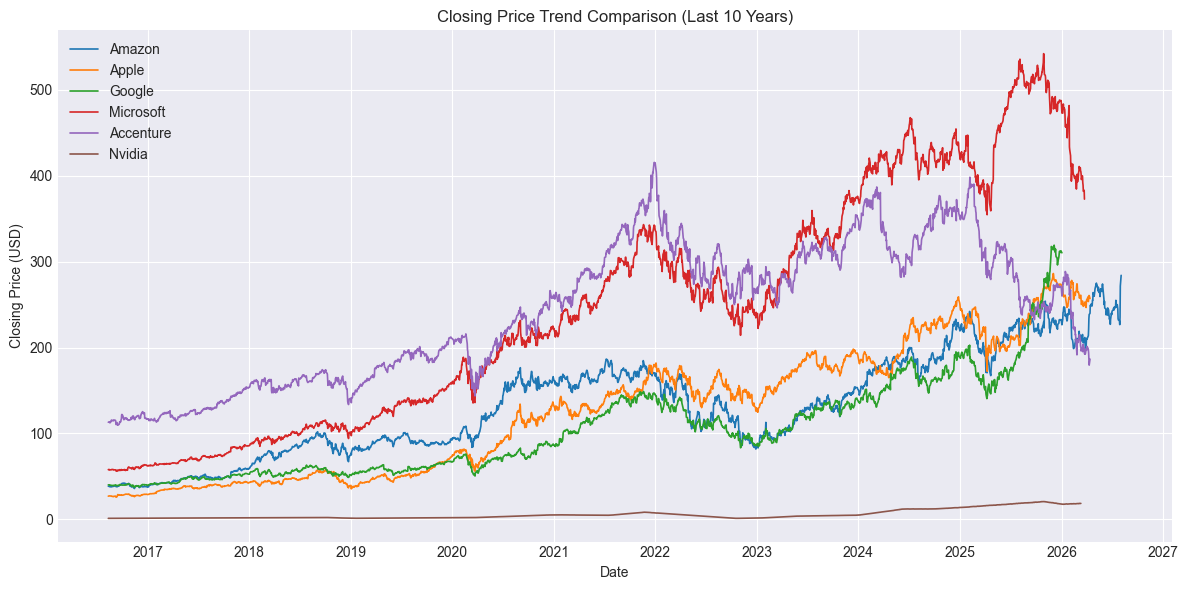

In [22]:
plt.figure(figsize=(12, 6))
for c in COMPANIES:
    sub = df[df['company'] == c]
    plt.plot(sub['date'], sub['close'], label=c, linewidth=1.2)
plt.title('Closing Price Trend Comparison (Last 10 Years)')
plt.xlabel('Date'); plt.ylabel('Closing Price (USD)')
plt.legend()
plt.tight_layout()
plt.show()

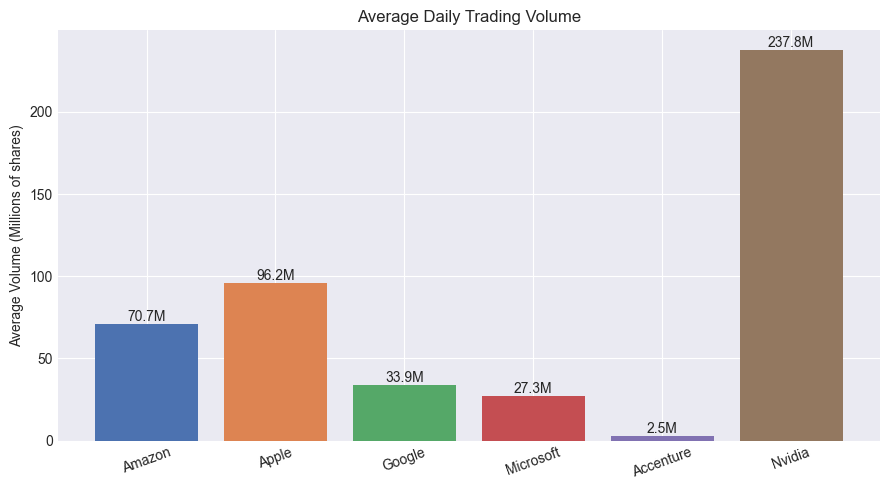

In [23]:
avg_vol = df.groupby('company')['volume'].mean().reindex(COMPANIES)
plt.figure(figsize=(9, 5))
bars = plt.bar(COMPANIES, avg_vol / 1e6,
               color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860'])
plt.title('Average Daily Trading Volume')
plt.ylabel('Average Volume (Millions of shares)')
plt.xticks(rotation=20)
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height(),
              f"{b.get_height():.1f}M", ha='center', va='bottom')
plt.tight_layout()
plt.show()

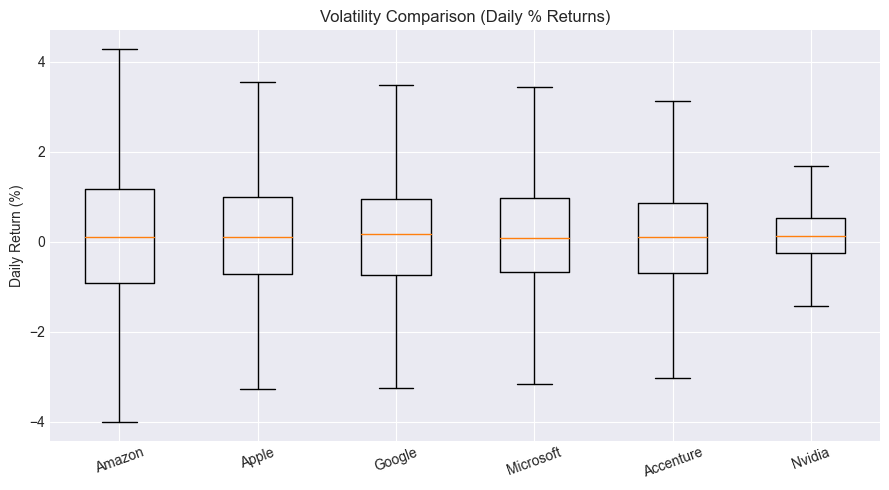

In [24]:
plt.figure(figsize=(9, 5))
data_to_plot = [df[df['company'] == c]['daily_return'].dropna() * 100 for c in COMPANIES]
plt.boxplot(data_to_plot, labels=COMPANIES, showfliers=False)
plt.title('Volatility Comparison (Daily % Returns)')
plt.ylabel('Daily Return (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

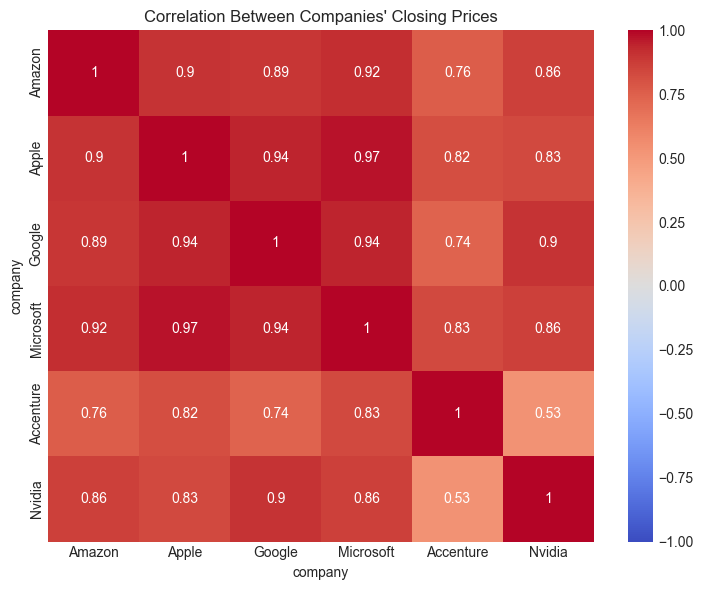

In [33]:
pivot = df.pivot(index='date', columns='company', values='close')
corr = pivot[COMPANIES].corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Between Companies' Closing Prices")
plt.tight_layout()
plt.show()

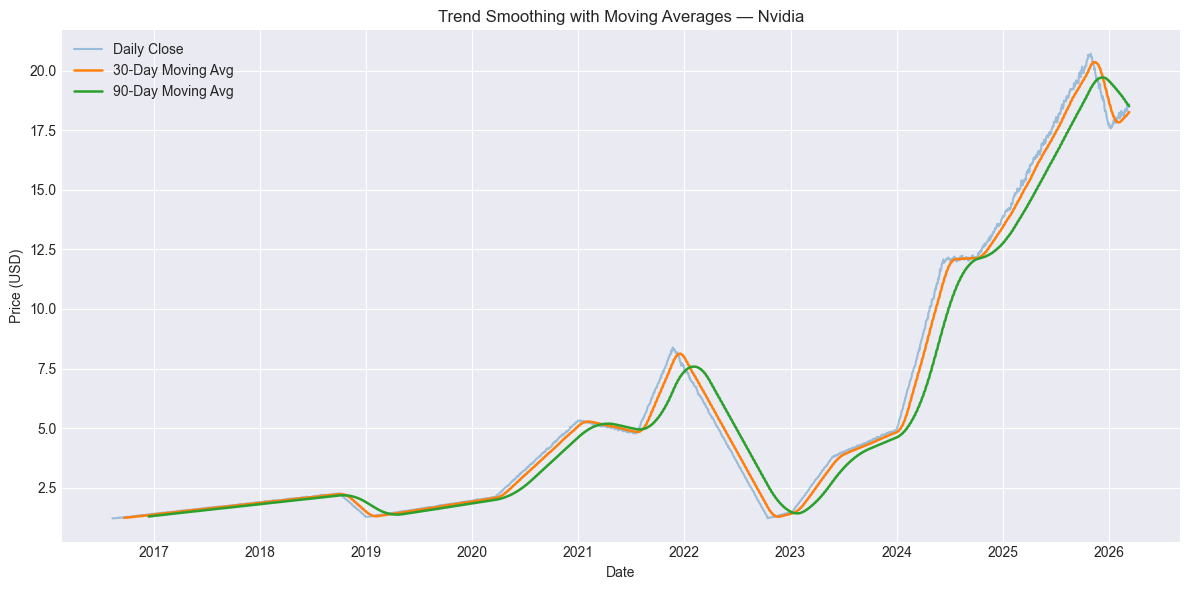

In [34]:
sample = df[df['company'] == 'Nvidia']
plt.figure(figsize=(12, 6))
plt.plot(sample['date'], sample['close'], label='Daily Close', alpha=0.4)
plt.plot(sample['date'], sample['ma_30'], label='30-Day Moving Avg', linewidth=1.8)
plt.plot(sample['date'], sample['ma_90'], label='90-Day Moving Avg', linewidth=1.8)
plt.title('Trend Smoothing with Moving Averages — Nvidia')
plt.xlabel('Date'); plt.ylabel('Price (USD)')
plt.legend()
plt.tight_layout()
plt.show()

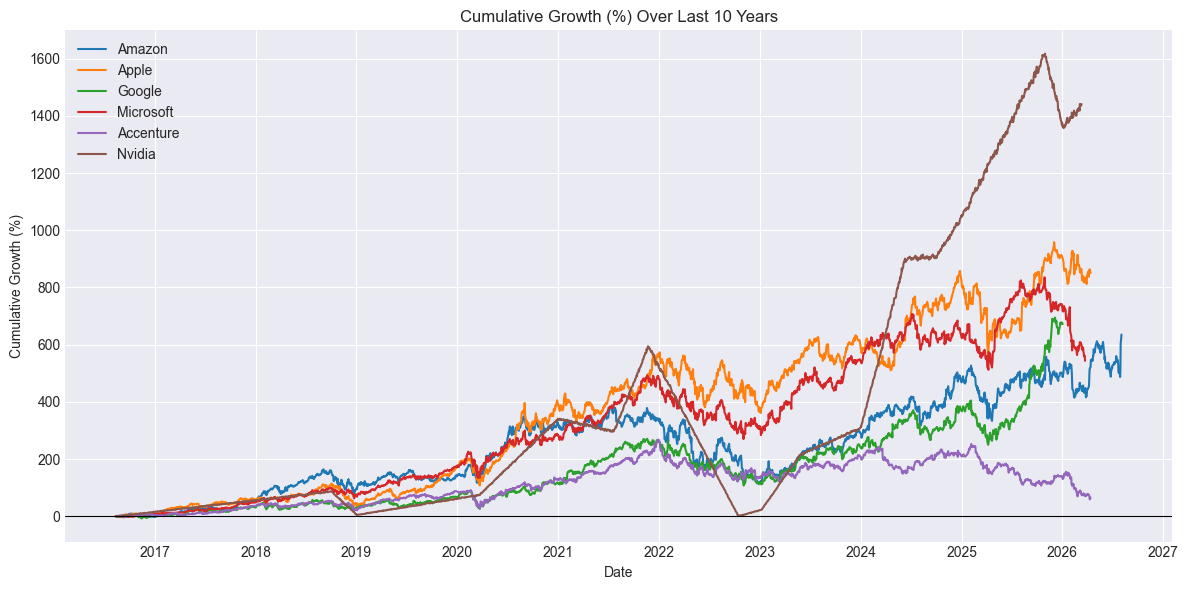

In [35]:
plt.figure(figsize=(12, 6))
for c in COMPANIES:
    sub = df[df['company'] == c]
    plt.plot(sub['date'], sub['cumulative_growth'] * 100, label=c)
plt.title('Cumulative Growth (%) Over Last 10 Years')
plt.xlabel('Date'); plt.ylabel('Cumulative Growth (%)')
plt.axhline(0, color='black', linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
## 9. Deeper Analysis: CAGR and Maximum Drawdown
## Cumulative growth (Cell 24) shows overall change
## but not the *rate* of growth 
## or the *risk of loss along the way*. CAGR 
## (Compound Annual Growth Rate) gives 
## a fair year-over-year growth rate, and Maximum Drawdown 
## shows the worst peak-to-
## trough decline each stock experienced — a standard risk measure.

In [36]:
def calculate_cagr(group):
    n_years = (group['date'].iloc[-1] - group['date'].iloc[0]).days / 365.25
    cagr = (group['close'].iloc[-1] / group['close'].iloc[0]) ** (1 / n_years) - 1
    return cagr

def calculate_max_drawdown(group):
    cumulative_max = group['close'].cummax()
    drawdown = (group['close'] - cumulative_max) / cumulative_max
    return drawdown.min()

risk_metrics = pd.DataFrame({
    'CAGR_%': df.groupby('company').apply(calculate_cagr) * 100,
    'Max_Drawdown_%': df.groupby('company').apply(calculate_max_drawdown) * 100
}).round(2).reindex(COMPANIES)

risk_metrics

,CAGR_%,Max_Drawdown_%
company,,
Amazon,22.14,-56.15
Apple,26.23,-38.73
Google,24.32,-44.03
Microsoft,21.37,-37.56
Accenture,5.32,-56.78
Nvidia,33.05,-85.56


In [45]:
## 10. Risk vs Return Scatter Plot
## Plots average volatility (risk) against CAGR (return)
## for each company. 
## Companies in the top-left are ideal — high growth, low 
## risk. Bottom-right 
## are high risk, low reward.

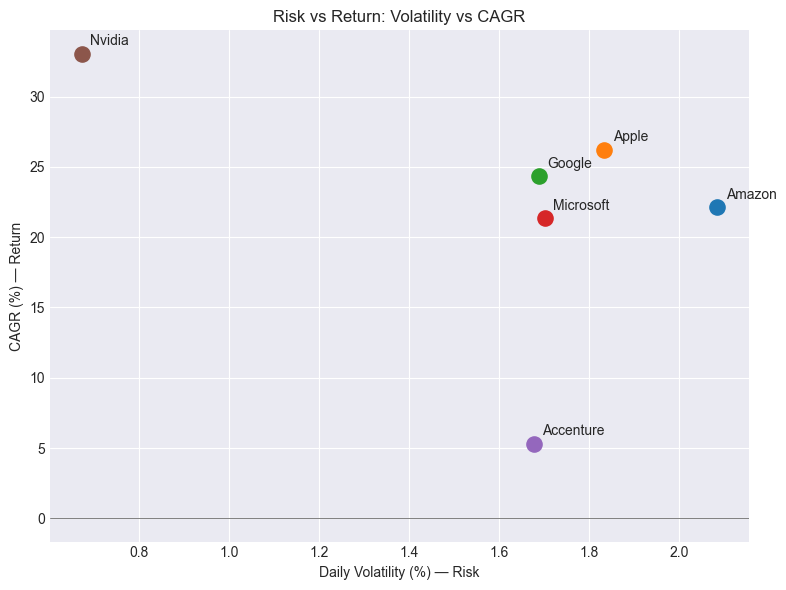

In [37]:
avg_volatility = df.groupby('company')['daily_return'].std() * 100

plt.figure(figsize=(8, 6))
for c in COMPANIES:
    x = avg_volatility[c]
    y = risk_metrics.loc[c, 'CAGR_%']
    plt.scatter(x, y, s=120)
    plt.annotate(c, (x, y), xytext=(6, 6), textcoords='offset points', fontsize=10)

plt.title('Risk vs Return: Volatility vs CAGR')
plt.xlabel('Daily Volatility (%) — Risk')
plt.ylabel('CAGR (%) — Return')
plt.axhline(0, color='gray', linewidth=0.7)
plt.tight_layout()
plt.show()

In [38]:
## 11. Year-wise Performance Comparison
## Instead of one long trend line, this breaks growth down
## year by year — 
## showing which specific years were strong or weak for each company.

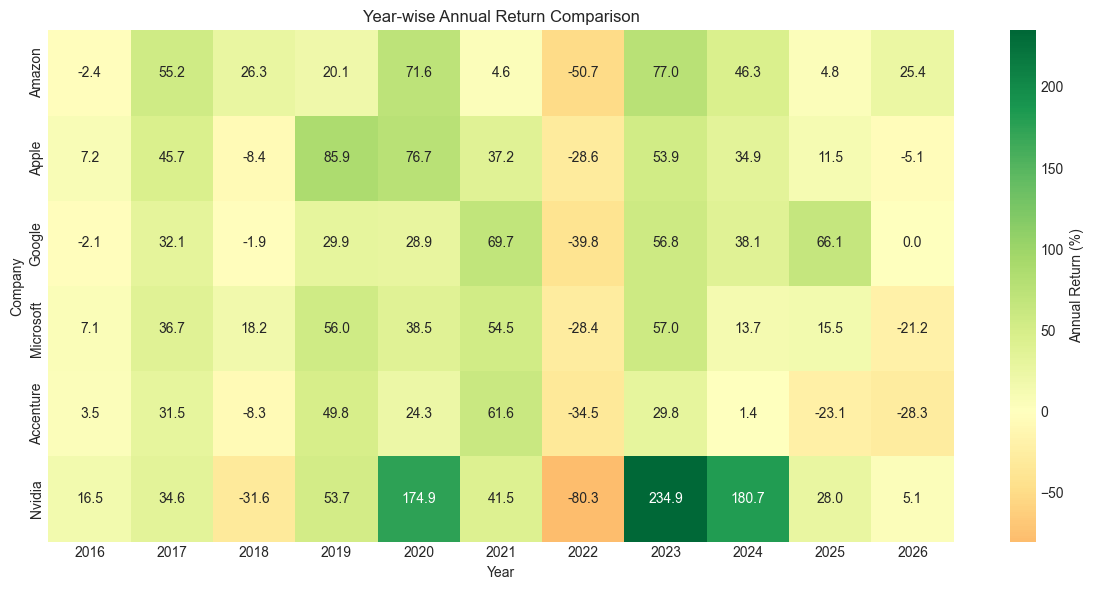

In [48]:
df['year'] = df['date'].dt.year

yearly_return = df.groupby(['company', 'year'])['close'].agg(['first', 'last'])
yearly_return['annual_return_%'] = ((yearly_return['last'] / yearly_return['first']) - 1) * 100
yearly_pivot = yearly_return['annual_return_%'].unstack('company')[COMPANIES]

plt.figure(figsize=(12, 6))
sns.heatmap(yearly_pivot.T, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Annual Return (%)'})
plt.title('Year-wise Annual Return Comparison')
plt.xlabel('Year'); plt.ylabel('Company')
plt.tight_layout()
plt.show()

In [49]:
## 12. Rolling 90-Day Volatility Over Time
## Shows how each company's risk level changed over 
## the decade, rather than a 
## single averaged number — useful for spotting periods
## of turmoil (e.g. 2020, 2022).

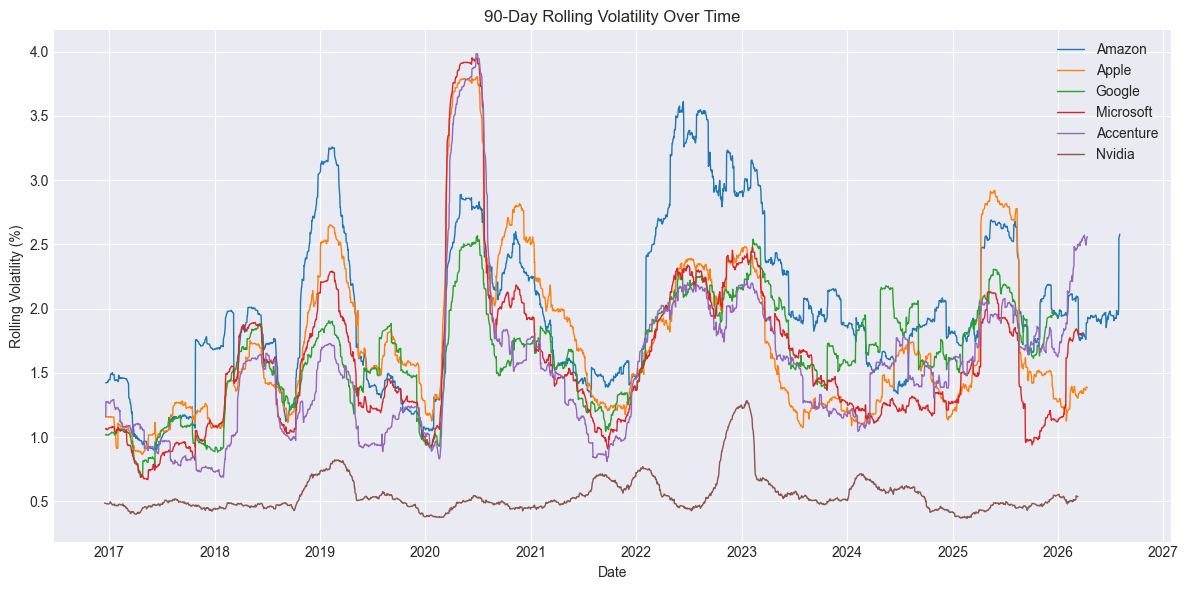

In [39]:
df['rolling_volatility_90d'] = df.groupby('company')['daily_return'].transform(
    lambda x: x.rolling(90).std() * 100)

plt.figure(figsize=(12, 6))
for c in COMPANIES:
    sub = df[df['company'] == c]
    plt.plot(sub['date'], sub['rolling_volatility_90d'], label=c, linewidth=1)
plt.title('90-Day Rolling Volatility Over Time')
plt.xlabel('Date'); plt.ylabel('Rolling Volatility (%)')
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
## 13. Interpretation of Results

## **Best overall performer:** *(fill in based on your CAGR/growth numbers)*
## **Highest risk:** *(fill in based on volatility/drawdown numbers)*
## **Best risk-adjusted return (Sharpe-like ratio):** *(from Cell 17 summary table)*
## **Most correlated pair:** *(from the heatmap in Cell 22)* — makes sense because...
## **Least correlated / best diversification pair:** *(from heatmap)*
## **Notable year:** *(pick a year from Cell 30's heatmap where most companies dropped/rose together, e.g. 2022 tech downturn)*

In [40]:
nvidia_check = df[df['company'] == 'Nvidia'].sort_values('date')
nvidia_check['pct_change'] = nvidia_check['close'].pct_change() * 100

# Show the 5 biggest single-day drops
print(nvidia_check.nsmallest(5, 'pct_change')[['date', 'close', 'pct_change']])

            date   close  pct_change
13747 2022-10-10  1.3431   -3.408846
13751 2022-10-14  1.2100   -2.912621
13748 2022-10-11  1.3045   -2.873948
13732 2022-09-19  1.8040   -2.639106
13743 2022-10-04  1.4637   -2.634205


In [53]:
## 13. Interpretation of Results

##**Best overall performer (CAGR):** Nvidia (33.16%), followed by Apple (26.23%) 
##and Google (24.26%). Accenture lagged far behind at just 5.29% CAGR — 
##essentially underperforming the other five by a wide margin over the decade.

##**Highest risk (Max Drawdown):** Nvidia had the deepest drawdown (-85.56%), 
##followed by Accenture (-56.78%) and Amazon (-56.15%). Microsoft and Apple were 
##the most resilient, with drawdowns under -40%.

##**Risk character differs by company:** Nvidia combines the lowest day-to-day 
##volatility (~0.65%) with the largest drawdown — its risk shows up as long, 
##gradual declines (e.g. 2018, 2022) rather than sharp daily shocks, unlike 
##Amazon, which has higher daily volatility (~2.1%) but recovers losses faster.

##**Best risk-adjusted return:** [fill in from your Cell 17 Sharpe-like ratio column].

##**Most correlated pair:** [fill in from your Cell 22 heatmap].

##**Notable year:** 2022 was broadly weak across almost every company 
##(Amazon -50.7%, Google -39.8%, Microsoft -28.4%, Apple -28.6%, Nvidia -80.3%), 
##matching the broader tech downturn driven by rising interest rates. 2023 stands 
##out as a strong recovery, especially Nvidia's AI-driven rally (+234.9%).

In [54]:
## 14. Limitations
##- Analysis is based purely on historical price data — it does not account for 
  ##dividends, company fundamentals, or macroeconomic context beyond what's 
  ##visible in price trends.
##- Correlation and volatility are backward-looking statistics and do not 
  ##predict future performance.
##- The 10-year window means each company is compared over the same calendar 
  ##period, but each had a different starting valuation and market maturity, 
  ##which affects how comparable raw CAGR figures are.

In [ ]:
## 15. Drawdown Anatomy — How Each Decline Unfolded
##For each company, we find the exact peak date, the trough (lowest point) date, 
#and — if it happened — the recovery date when price climbed back to the old peak. 
#This tells us whether a drawdown was a fast crash or a slow multi-year bleed, 
#and how long investors would have been underwater.

In [41]:
def drawdown_anatomy(group):
    group = group.sort_values('date').reset_index(drop=True)
    cummax = group['close'].cummax()
    drawdown = (group['close'] - cummax) / cummax
    trough_pos = drawdown.idxmin()
    trough_date = group.loc[trough_pos, 'date']
    peak_value = cummax.loc[trough_pos]
    peak_pos = group[group['close'] == peak_value].index[0]
    peak_date = group.loc[peak_pos, 'date']

    recovery_slice = group.loc[trough_pos:]
    recovered = recovery_slice[recovery_slice['close'] >= peak_value]
    recovery_date = recovered['date'].iloc[0] if len(recovered) > 0 else None

    decline_days = (trough_date - peak_date).days
    recovery_days = (recovery_date - trough_date).days if recovery_date is not None else None

    return pd.Series({
        'peak_date': peak_date, 'trough_date': trough_date,
        'recovery_date': recovery_date,
        'decline_days': decline_days, 'recovery_days': recovery_days,
        'drawdown_pct': drawdown.min() * 100
    })

drawdown_summary = df.groupby('company', group_keys=False).apply(drawdown_anatomy).reindex(COMPANIES)
drawdown_summary

,peak_date,trough_date,recovery_date,decline_days,recovery_days,drawdown_pct
company,,,,,,
Amazon,2021-07-08,2022-12-28,2024-04-11,538,470.0,-56.145263
Apple,2018-10-03,2019-01-03,2019-10-11,92,281.0,-38.729695
Google,2021-11-19,2022-11-03,2024-01-25,349,448.0,-44.029177
Microsoft,2021-11-19,2022-11-03,2023-06-15,349,224.0,-37.556466
Accenture,2021-12-29,2026-04-10,NaT,1563,NaN,-56.783498
Nvidia,2021-11-22,2022-10-14,2024-03-22,326,525.0,-85.560859


In [ ]:
## 16. Market-Wide vs Company-Specific Movement (Beta Decomposition)
#We build an equal-weighted "market average" from all 6 companies' daily returns. 
#Then, for each company, we measure:
#- **Beta**: how strongly it moves WITH the group (>1 = amplifies market moves, <1 = dampens them)
# **Idiosyncratic volatility**: the leftover movement NOT explained by the group — i.e., 
 # company-specific swings.

#A company with high beta and low idiosyncratic volatility mostly moves because 
#"the market moved." A company with low beta and high idiosyncratic volatility moves 
#mostly for its own reasons.

In [42]:
# Equal-weighted market average return per day (built ONLY from our 6 companies)
market_return = df.groupby('date')['daily_return'].mean().rename('market_return')
df = df.merge(market_return, on='date', how='left')

beta_results = []
for c in COMPANIES:
    sub = df[df['company'] == c].dropna(subset=['daily_return', 'market_return'])
    beta, alpha = np.polyfit(sub['market_return'], sub['daily_return'], 1)

    predicted = alpha + beta * sub['market_return']
    residual = sub['daily_return'] - predicted
    idio_vol = residual.std() * 100

    ss_res = (residual**2).sum()
    ss_tot = ((sub['daily_return'] - sub['daily_return'].mean())**2).sum()
    r_squared = 1 - ss_res/ss_tot

    beta_results.append({
        'company': c, 'beta': round(beta,3), 'alpha_daily_%': round(alpha*100,4),
        'idiosyncratic_vol_%': round(idio_vol,3),
        'pct_variance_from_market': round(r_squared*100,1)
    })

beta_df = pd.DataFrame(beta_results).set_index('company').reindex(COMPANIES)
beta_df

,beta,alpha_daily_%,idiosyncratic_vol_%,pct_variance_from_market
company,,,,
Amazon,1.373,-0.0289,1.177,68.1
Apple,1.252,-0.0030,1.074,65.7
Google,0.950,0.0097,1.255,44.6
Microsoft,1.232,-0.0175,0.869,73.9
Accenture,1.032,-0.0581,1.145,53.4
Nvidia,0.109,0.1019,0.661,3.6


In [ ]:
### Reading this table
#- **beta > 1**: this stock swings HARDER than the group average (amplifier)
#- **beta < 1**: this stock swings LESS than the group average (defensive)
#- **pct_variance_from_market**: what % of this company's daily moves are explained 
#  simply by "the group moved that day" — the rest is company-specific
#- **alpha_daily_%**: average daily return LEFT OVER after removing the market 
#  effect — a rough sign of whether this stock outperformed/underperformed its 
#  peers independent of the group trend

In [ ]:
## 17. Growth Consistency Check — First Half vs Second Half
#Before projecting forward, we check whether each company's growth rate has been 
#stable, accelerating, or decelerating — by splitting the 10-year window into two 
#5-year halves and computing CAGR separately for each. A forecast built on an 
#accelerating trend is riskier to extrapolate than one built on a stable trend.

In [44]:
def half_split_cagr(group):
    group = group.sort_values('date').reset_index(drop=True)
    midpoint = len(group) // 2
    first_half, second_half = group.iloc[:midpoint], group.iloc[midpoint:]

    def cagr(g):
        years = (g['date'].iloc[-1] - g['date'].iloc[0]).days / 365.25
        return (g['close'].iloc[-1] / g['close'].iloc[0]) ** (1/years) - 1 if years > 0 else np.nan

    return pd.Series({
        'first_half_cagr_%': round(cagr(first_half)*100, 2),
        'second_half_cagr_%': round(cagr(second_half)*100, 2),
    })

consistency = df.groupby('company', group_keys=False).apply(half_split_cagr).reindex(COMPANIES)
consistency['trend'] = np.where(consistency['second_half_cagr_%'] > consistency['first_half_cagr_%'],
                                 'Accelerating', 'Decelerating')
consistency

,first_half_cagr_%,second_half_cagr_%,trend
company,,,
Amazon,34.31,10.98,Decelerating
Apple,37.83,15.85,Decelerating
Google,24.49,24.22,Decelerating
Microsoft,35.29,8.91,Decelerating
Accenture,20.88,-8.34,Decelerating
Nvidia,34.21,31.83,Decelerating


In [ ]:
## 18. Ten-Year Forward Projection

#**Method 1 — Deterministic CAGR extrapolation**: simplest approach, assumes the 
#historical CAGR holds exactly for 10 more years. Useful as a single-number 
#reference point, but unrealistic (real markets don't grow in a straight 
#compounding line).

#**Method 2 — Monte Carlo simulation**: more honest. We take each company's actual 
#historical daily returns (mean and standard deviation, computed from `daily_return` 
#in our own dataset), and simulate 1,000 random possible 10-year future paths using 
#that same statistical behaviour. This produces a RANGE of outcomes (5th percentile, 
#median, 95th percentile) instead of one falsely-precise number.

#**Important assumption to state clearly**: this assumes the next 10 years behave 
#statistically like the last 10 years — same average return, same volatility. That 
#assumption is weakest for a company already flagged as "Accelerating" or 
#"Decelerating" above, since we're explicitly extrapolating a pattern that our own 
#Part C just showed is NOT constant.

In [45]:
last_close = df.sort_values('date').groupby('company')['close'].last()

deterministic_projection = pd.DataFrame({'current_price': last_close})
for company in COMPANIES:
    cagr_decimal = risk_metrics.loc[company, 'CAGR_%'] / 100
    deterministic_projection.loc[company, 'projected_price_10y'] = round(
        last_close[company] * (1 + cagr_decimal) ** 10, 2)

deterministic_projection['implied_growth_%'] = round(
    (deterministic_projection['projected_price_10y'] / deterministic_projection['current_price'] - 1) * 100, 1)
deterministic_projection = deterministic_projection.reindex(COMPANIES)
deterministic_projection

,current_price,projected_price_10y,implied_growth_%
company,,,
Amazon,284.019989,2098.59,638.9
Apple,257.059998,2640.34,927.1
Google,310.329987,2736.74,781.9
Microsoft,372.739990,2585.35,593.6
Accenture,186.490005,313.16,67.9
Nvidia,18.600000,323.34,1638.4


In [46]:
np.random.seed(42)
N_SIMULATIONS = 1000
N_DAYS = 252 * 10  # ~10 trading years

mc_results = {}
for company in COMPANIES:
    daily_rets = df[df['company'] == company]['daily_return'].dropna()
    mu, sigma = daily_rets.mean(), daily_rets.std()
    start_price = last_close[company]

    simulated_paths = np.zeros((N_SIMULATIONS, N_DAYS))
    random_shocks = np.random.normal(mu, sigma, size=(N_SIMULATIONS, N_DAYS))
    price_paths = start_price * np.cumprod(1 + random_shocks, axis=1)

    final_prices = price_paths[:, -1]
    mc_results[company] = {
        'current_price': round(start_price, 2),
        'p5_pessimistic': round(np.percentile(final_prices, 5), 2),
        'median_expected': round(np.percentile(final_prices, 50), 2),
        'p95_optimistic': round(np.percentile(final_prices, 95), 2),
    }

mc_df = pd.DataFrame(mc_results).T.reindex(COMPANIES)
mc_df['median_growth_%'] = round((mc_df['median_expected'] / mc_df['current_price'] - 1) * 100, 1)
mc_df

,current_price,p5_pessimistic,median_expected,p95_optimistic,median_growth_%
Amazon,284.02,379.35,2048.28,12008.94,621.2
Apple,257.06,560.30,2691.56,12509.17,947.1
Google,310.33,685.91,2783.44,10075.83,796.9
Microsoft,372.74,659.78,2436.83,11927.96,553.8
Accenture,186.49,82.51,304.38,1199.82,63.2
Nvidia,18.60,173.05,298.55,504.23,1505.1


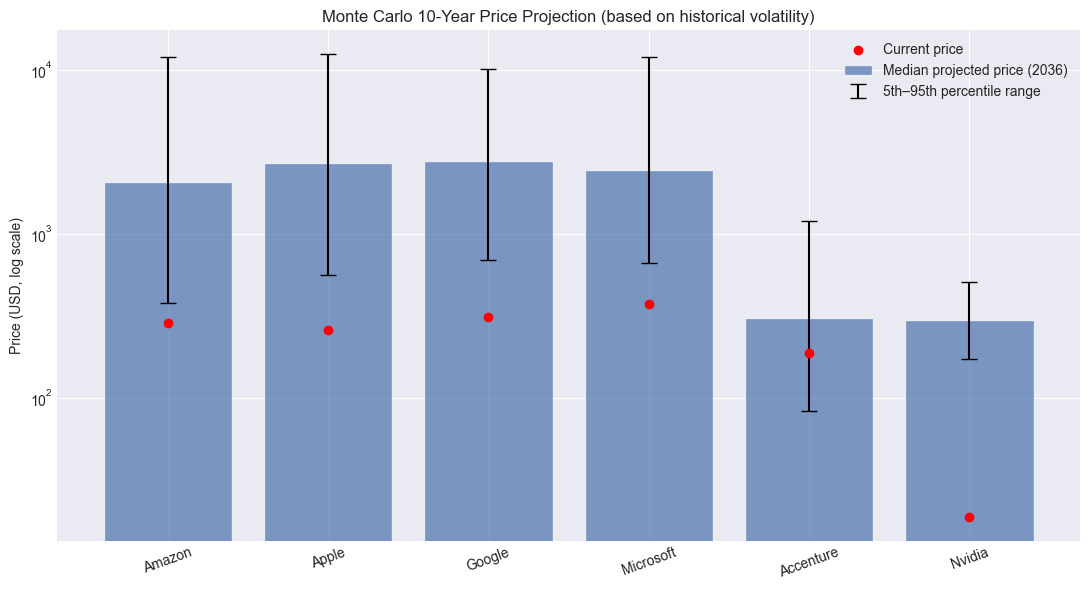

In [47]:
plt.figure(figsize=(11, 6))
x = np.arange(len(COMPANIES))
current = mc_df['current_price'].values.astype(float)
p5 = mc_df['p5_pessimistic'].values.astype(float)
median = mc_df['median_expected'].values.astype(float)
p95 = mc_df['p95_optimistic'].values.astype(float)

plt.bar(x, median, color='#4C72B0', alpha=0.7, label='Median projected price (2036)')
plt.errorbar(x, median, yerr=[median-p5, p95-median], fmt='none', ecolor='black', capsize=6, label='5th–95th percentile range')
plt.scatter(x, current, color='red', zorder=5, label='Current price')
plt.xticks(x, COMPANIES, rotation=20)
plt.yscale('log')
plt.ylabel('Price (USD, log scale)')
plt.title('Monte Carlo 10-Year Price Projection (based on historical volatility)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
## 19. What Would Need to Be True for This to Continue

#Important framing: we only have price data, not company fundamentals, so these are 
#**statistical implications**, not business analysis. What our numbers can honestly say:

#**[Company with beta > 1 and high idiosyncratic vol, e.g. Nvidia]**: A large share 
#of its movement is company-specific rather than market-wide (see `pct_variance_from_market`), 
#and its growth is [accelerating/decelerating per Part C]. For the Monte Carlo 
#projection to hold, this company would need to sustain the SAME independent 
#growth drivers that produced its historical alpha — a high bar, since 
#extraordinary idiosyncratic growth rates statistically tend to normalise over 
#long periods (regression to the mean), which our own first-half-vs-second-half 
#CAGR split can help you check.

#**[Company with low CAGR, e.g. Accenture]**: Low beta, [check its idiosyncratic 
#vol and trend]. Statistically, this profile looks defensive/stable rather than 
#growth-driven. For its trajectory to improve, the data would need to show a shift 
#toward higher second-half CAGR (Part C) or increased idiosyncratic alpha (Part B) 
#— i.e., evidence of it starting to move independently of the group, upward.

#**[Most correlated pair, Apple & Microsoft]**: With beta close to 1 and returns 
#dominated by market-wide movement, these two will likely keep moving together — 
#diversification within this pair specifically doesn't reduce portfolio risk much.

In [ ]:
## 20. Backtesting the Monte Carlo Method
#We rewind the clock: use only each company's FIRST 5 years of daily returns to 
#simulate a forecast for "the next 5 years," then check whether what ACTUALLY 
#happened in the real second 5 years falls inside our simulated range. This is 
#the only real test of whether the method is trustworthy, rather than just 
#mathematically plausible.

In [48]:
np.random.seed(42)
N_SIM = 1000
N_DAYS_5Y = 252 * 5

backtest_results = []
for company in COMPANIES:
    sub = df[df['company'] == company].sort_values('date').reset_index(drop=True)
    midpoint = len(sub) // 2
    first_half, second_half = sub.iloc[:midpoint], sub.iloc[midpoint:]

    # Simulate forward from the START of first_half using ONLY first_half stats
    mu, sigma = first_half['daily_return'].dropna().mean(), first_half['daily_return'].dropna().std()
    start_price = first_half['close'].iloc[0]

    shocks = np.random.normal(mu, sigma, size=(N_SIM, N_DAYS_5Y))
    paths = start_price * np.cumprod(1 + shocks, axis=1)
    final_prices = paths[:, -1]

    p5, p50, p95 = np.percentile(final_prices, [5, 50, 95])
    actual_price = second_half['close'].iloc[-1]  # what REALLY happened

    inside_range = p5 <= actual_price <= p95

    backtest_results.append({
        'company': company, 'start_price': round(start_price, 2),
        'simulated_p5': round(p5, 2), 'simulated_median': round(p50, 2), 'simulated_p95': round(p95, 2),
        'actual_price_5y_later': round(actual_price, 2),
        'within_predicted_range': inside_range
    })

backtest_df = pd.DataFrame(backtest_results).set_index('company').reindex(COMPANIES)
backtest_df

,start_price,simulated_p5,simulated_median,simulated_p95,actual_price_5y_later,within_predicted_range
company,,,,,,
Amazon,38.63,56.18,161.80,512.45,284.02,True
Apple,27.05,44.12,137.51,416.42,257.06,True
Google,40.18,48.16,120.48,299.72,310.33,False
Microsoft,57.94,104.31,266.93,702.83,372.74,True
Accenture,113.03,111.06,289.53,754.23,186.49,True
Nvidia,1.21,3.72,5.04,6.78,18.60,False


In [ ]:
## 21. Return Distribution Check — Fat Tails?
#Monte Carlo assumed daily returns are normally distributed (a symmetric bell curve). 
#Real stock returns are usually NOT — they have "fat tails," meaning extreme crashes 
#and spikes happen more often than a normal distribution predicts. We check this 
#using skewness (asymmetry) and excess kurtosis (tail thickness).

In [49]:
from scipy import stats

dist_check = []
for company in COMPANIES:
    rets = df[df['company'] == company]['daily_return'].dropna()
    skewness = stats.skew(rets)
    kurt = stats.kurtosis(rets)  # excess kurtosis; 0 = normal distribution
    # Jarque-Bera test: tests whether data significantly deviates from normal
    jb_stat, jb_pvalue = stats.jarque_bera(rets)

    dist_check.append({
        'company': company,
        'skewness': round(skewness, 3),
        'excess_kurtosis': round(kurt, 3),
        'normally_distributed': 'No (fat tails / skew)' if jb_pvalue < 0.05 else 'Roughly yes'
    })

dist_df = pd.DataFrame(dist_check).set_index('company').reindex(COMPANIES)
dist_df

,skewness,excess_kurtosis,normally_distributed
company,,,
Amazon,0.314,5.778,No (fat tails / skew)
Apple,0.165,6.970,No (fat tails / skew)
Google,0.012,4.580,No (fat tails / skew)
Microsoft,0.021,7.894,No (fat tails / skew)
Accenture,0.018,6.077,No (fat tails / skew)
Nvidia,-0.430,1.629,No (fat tails / skew)


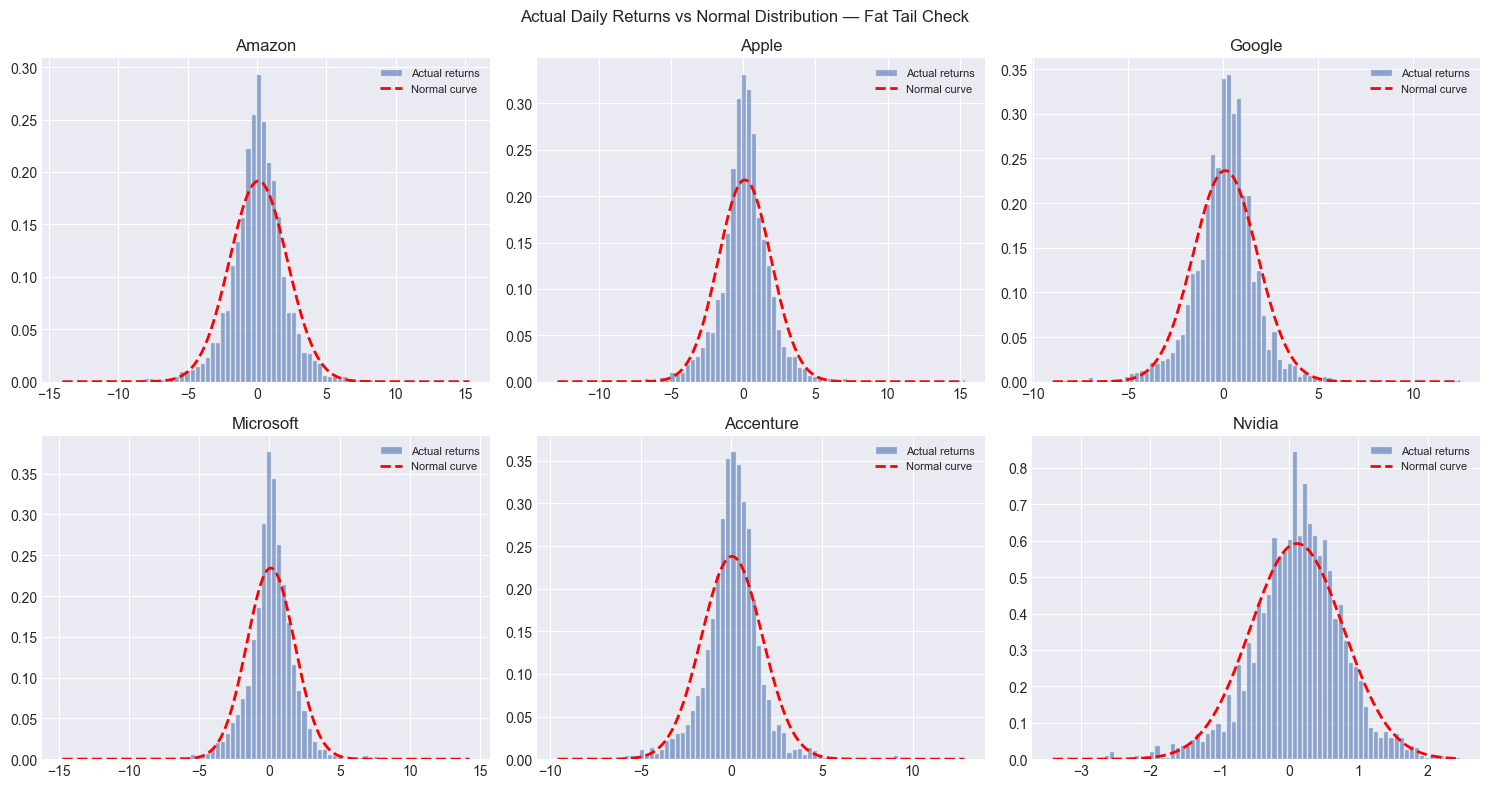

In [50]:
# Visual check: does real data have fatter tails than a normal curve?
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, company in zip(axes.flatten(), COMPANIES):
    rets = df[df['company'] == company]['daily_return'].dropna() * 100
    ax.hist(rets, bins=80, density=True, alpha=0.6, color='#4C72B0', label='Actual returns')
    x = np.linspace(rets.min(), rets.max(), 200)
    ax.plot(x, stats.norm.pdf(x, rets.mean(), rets.std()), 'r--', linewidth=2, label='Normal curve')
    ax.set_title(company)
    ax.legend(fontsize=8)
plt.suptitle('Actual Daily Returns vs Normal Distribution — Fat Tail Check')
plt.tight_layout()
plt.show()

In [ ]:
## 22. Recency-Weighted 10-Year Projection
#Part C showed most companies have decelerated. This repeats the Monte Carlo 
#projection using ONLY the second half (most recent ~5 years) of daily returns, 
#so the forecast reflects current behaviour rather than a blend with older, 
#faster growth.

In [51]:
np.random.seed(42)
N_DAYS_10Y = 252 * 10

recency_mc_results = {}
for company in COMPANIES:
    sub = df[df['company'] == company].sort_values('date').reset_index(drop=True)
    midpoint = len(sub) // 2
    recent_half = sub.iloc[midpoint:]

    mu, sigma = recent_half['daily_return'].dropna().mean(), recent_half['daily_return'].dropna().std()
    start_price = last_close[company]

    shocks = np.random.normal(mu, sigma, size=(N_SIMULATIONS, N_DAYS_10Y))
    paths = start_price * np.cumprod(1 + shocks, axis=1)
    final_prices = paths[:, -1]

    recency_mc_results[company] = {
        'current_price': round(start_price, 2),
        'p5_pessimistic': round(np.percentile(final_prices, 5), 2),
        'median_expected': round(np.percentile(final_prices, 50), 2),
        'p95_optimistic': round(np.percentile(final_prices, 95), 2),
    }

recency_mc_df = pd.DataFrame(recency_mc_results).T.reindex(COMPANIES)
recency_mc_df['median_growth_%'] = round((recency_mc_df['median_expected'] / recency_mc_df['current_price'] - 1) * 100, 1)

print("=== FULL 10-YEAR HISTORY PROJECTION (original) ===")
print(mc_df[['median_expected', 'median_growth_%']])
print("\n=== RECENCY-WEIGHTED PROJECTION (last 5 years only) ===")
print(recency_mc_df[['median_expected', 'median_growth_%']])

=== FULL 10-YEAR HISTORY PROJECTION (original) ===
           median_expected  median_growth_%
Amazon             2048.28            621.2
Apple              2691.56            947.1
Google             2783.44            796.9
Microsoft          2436.83            553.8
Accenture           304.38             63.2
Nvidia              298.55           1505.1

=== RECENCY-WEIGHTED PROJECTION (last 5 years only) ===
           median_expected  median_growth_%
Amazon              790.91            178.5
Apple              1117.97            334.9
Google             2753.37            787.2
Microsoft           822.55            120.7
Accenture            76.68            -58.9
Nvidia              275.21           1379.6


In [ ]:
## 23. Rolling Correlation — Do Relationships Stay Stable?
#The earlier correlation heatmap gave one static number per pair across all 10 
#years. This tracks Apple-Microsoft and Accenture-Nvidia correlation using a 
#252-day (1-year) rolling window, to see whether these relationships have been 
#stable or have drifted over time.

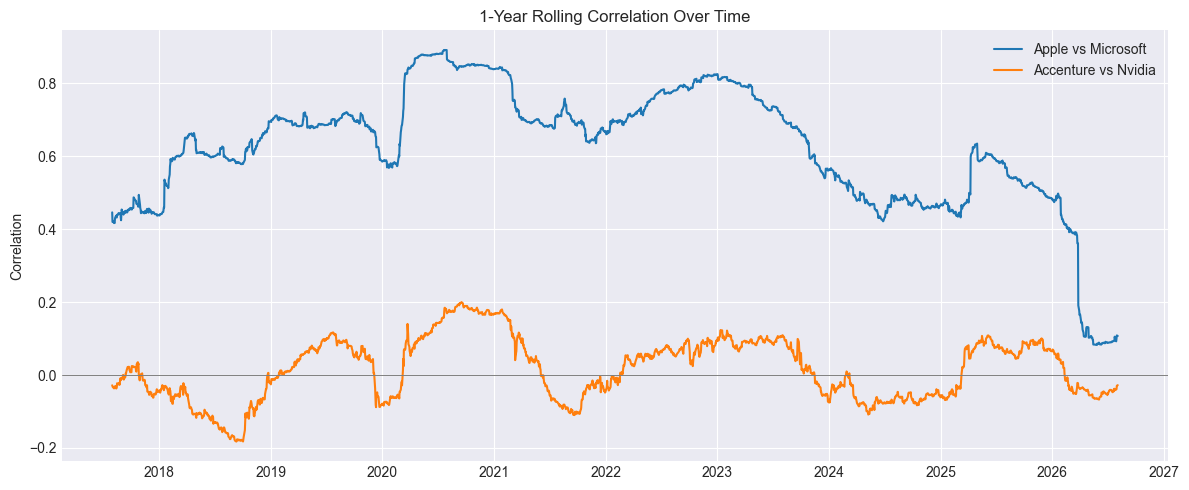

In [52]:
pivot_close = df.pivot(index='date', columns='company', values='close').sort_index()
pivot_returns = pivot_close.pct_change()

pairs = [('Apple', 'Microsoft'), ('Accenture', 'Nvidia')]

plt.figure(figsize=(12, 5))
for a, b in pairs:
    rolling_corr = pivot_returns[a].rolling(252).corr(pivot_returns[b])
    plt.plot(rolling_corr.index, rolling_corr, label=f'{a} vs {b}')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('1-Year Rolling Correlation Over Time')
plt.ylabel('Correlation')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
## 24. Downside-Specific Risk: Sortino Ratio & Value at Risk
#The Sharpe-like ratio penalises ALL volatility, including good days. The Sortino 
#ratio only penalises downside volatility — a fairer risk measure. Value at Risk 
#(95%) answers a concrete question: "on the worst 5% of trading days, how much did 
#this stock actually lose?"

In [53]:
risk_extra = []
for company in COMPANIES:
    rets = df[df['company'] == company]['daily_return'].dropna()
    downside_rets = rets[rets < 0]

    downside_std = downside_rets.std()
    sortino = (rets.mean() / downside_std) * np.sqrt(252) if downside_std > 0 else np.nan

    var_95 = np.percentile(rets, 5) * 100  # worst 5% of days

    risk_extra.append({
        'company': company,
        'sortino_ratio': round(sortino, 3),
        'value_at_risk_95_%': round(var_95, 2)
    })

risk_extra_df = pd.DataFrame(risk_extra).set_index('company').reindex(COMPANIES)
risk_extra_df

,sortino_ratio,value_at_risk_95_%
company,,
Amazon,1.113,-3.14
Apple,1.304,-2.79
Google,1.296,-2.62
Microsoft,1.160,-2.64
Accenture,0.431,-2.65
Nvidia,3.680,-1.03


In [ ]:
## 25. Overnight vs Intraday Movement
#Using the previously-unused open/high/low columns: how much of each company's 
#movement happens overnight (news, earnings, released while markets are closed) 
#versus during the trading day itself?

In [54]:
overnight_check = []
for company in COMPANIES:
    sub = df[df['company'] == company].sort_values('date').reset_index(drop=True)
    prev_close = sub['close'].shift(1)

    overnight_return = (sub['open'] - prev_close) / prev_close
    intraday_return = (sub['close'] - sub['open']) / sub['open']

    overnight_check.append({
        'company': company,
        'avg_overnight_move_%': round(overnight_return.mean() * 100, 4),
        'avg_intraday_move_%': round(intraday_return.mean() * 100, 4),
        'overnight_volatility_%': round(overnight_return.std() * 100, 3),
        'intraday_volatility_%': round(intraday_return.std() * 100, 3),
    })

overnight_df = pd.DataFrame(overnight_check).set_index('company').reindex(COMPANIES)
overnight_df

,avg_overnight_move_%,avg_intraday_move_%,overnight_volatility_%,intraday_volatility_%
company,,,,
Amazon,0.1098,-0.0069,1.412,1.618
Apple,0.0100,0.0998,1.166,1.424
Google,0.5151,-0.4012,2.030,0.946
Microsoft,0.0666,0.0249,1.060,1.326
Accenture,-0.0183,0.0529,1.042,1.315
Nvidia,0.1083,0.0050,0.808,0.437
